# Default Settings

In [1]:
import rby1_sdk as rby
import time
import numpy as np
from matplotlib import pyplot as plt
import inspect

np.set_printoptions(suppress=True, precision=3, linewidth=300)  

ZERO_POS = {"torso":      np.deg2rad([0.0, 0.0, 0.0, 0.0, 0.0, 0.0]),
             "right_arm": np.deg2rad([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]),
             "left_arm":  np.deg2rad([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0])}

READY_POS = {"torso":     np.deg2rad([0.0, 45.0, -90.0,   45.0, 0.0,  0.0]),
            "right_arm":  np.deg2rad([0.0, -5.0,   0.0, -120.0, 0.0, 70.0, 0.0]),
            "left_arm":   np.deg2rad([0.0,  5.0,   0.0, -120.0, 0.0, 70.0, 0.0])}

PACK_POS = {"torso":      np.deg2rad([0.0, 80.0, -140.0,   60.0, 0.0,   0.0]),
            "right_arm":  np.deg2rad([0.0,  0.0,    0.0, -150.0, 0.0, 105.0, 0.0]),
            "left_arm":   np.deg2rad([0.0,  0.0,    0.0, -150.0, 0.0, 105.0, 0.0])}


PACK_POS_2 = {"torso":      np.deg2rad([0.0, 80.0, -140.0,   60.0, 0.0, 0.0]),
              "right_arm":  np.deg2rad([0.0,  0.0,    0.0, -150.0, 0.0, 0.0, 0.0]),
              "left_arm":   np.deg2rad([0.0,  0.0,    0.0, -150.0, 0.0, 0.0, 0.0])}



# Connect to Robot

In [ ]:
### 1. Address ###
# ROBOT_ADDRESS = "localhost:50051"           # For Docker Simulation
ROBOT_ADDRESS = "192.168.30.1:50051"        # For Real Robot

robot = rby.create_robot_a(ROBOT_ADDRESS)   # Robot Model is "A"
model = robot.model()
if not robot.connect():
    print("Could not connect to robot")
    exit(1)
else:
    print("Successfully connected to the robot!!")

Could not connect to robot


# Power ON the Robot

In [3]:
robot.power_on(".*")         # Turn on all the power (5v, 12v, 24v, 48v)

True

In [4]:
robot.servo_on(".*")         # Enable servo motors on all actuators

True

In [5]:
# Reset the fault control manager
robot.reset_fault_control_manager()

# Enable control manager with limited mode disabled
robot.enable_control_manager(unlimited_mode_enabled=True)

True

# Power OFF the Robot

In [9]:
robot.disable_control_manager()
robot.power_off(".*")  

True

In [9]:
def move_position(torso, right_arm, left_arm, minimum_time=10.0):
    rc_builder = rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder().set_body_command(
            rby.BodyComponentBasedCommandBuilder()
            # Set Torso Command with Joint Position Command
            .set_torso_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))  # For saturation
                .set_minimum_time(minimum_time)
                .set_position(torso)
            )
            # Set Right Command with Joint Position Command
            .set_right_arm_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))
                .set_minimum_time(minimum_time)
                .set_position(right_arm)
            )
            # Set Left Command with Joint Position Command
            .set_left_arm_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))
                .set_minimum_time(minimum_time)
                .set_position(left_arm)
            )
        )
    )
    rc = robot.send_command(rc_builder).get()
    return rc.finish_code == rby.RobotCommandFeedback.FinishCode.Ok

In [12]:
Desired_Pos = PACK_POS     # ZERO_POS, READY_POS, PACK_POS

move_position(Desired_Pos["torso"], Desired_Pos["right_arm"], Desired_Pos["left_arm"])

True

# Move to Zero Position

In [7]:
minimum_time = 5    # Consumed Time
rc_builder = rby.RobotCommandBuilder().set_command(
    rby.ComponentBasedCommandBuilder().set_body_command(
        rby.BodyComponentBasedCommandBuilder()
        # Set Torso Command with Joint Position Command
        .set_torso_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position([0.] * 6)     # Unit: rad / [Torso_0(Roll-ankle), Torso_1(Pitch-ankle), Torso_2(Pitch-knee), Torso_3(Pitch-hip), Torso_4(Roll-hip), Torso_5(Yaw)]
        )
        # Set Right Arm Command with Joint Position Command
        .set_right_arm_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position([0.] * 7)     # Unit: rad / [right_arm_0(Pitch-shoulder), right_arm_1(Roll-shoulder), right_arm_2(Yaw-shoulder), right_arm_3(Pitch-elbow), right_arm_4(Yaw-elbow), right_arm_5(Pitch-wrist), right_arm_6(Yaw-wrist)]
        )
        # Set Left Arm Command with Joint Position Command
        .set_left_arm_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position([0.] * 7)     # Unit: rad / [left_arm_0(Pitch-shoulder), left_arm_1(Roll-shoulder), left_arm_2(Yaw-shoulder), left_arm_3(Pitch-elbow), left_arm_4(Yaw-elbow), left_arm_5(Pitch-wrist), left_arm_6(Yaw-wrist)]
        )
    )
)
handler = robot.send_command(rc_builder)
feedback = handler.get()  # Wait for finish and get feedback from control
print(feedback.finish_code)

FinishCode.Ok


# Get Robot State

[‘right_wheel’, ‘left_wheel’, ‘torso_0’, ‘torso_1’, ‘torso_2’, ‘torso_3’, ‘torso_4’, ‘torso_5’, ‘right_arm_0’, ‘right_arm_1’, ‘right_arm_2’, ‘right_arm_3’, ‘right_arm_4’, ‘right_arm_5’, ‘right_arm_6’, ‘left_arm_0’, ‘left_arm_1’, ‘left_arm_2’, ‘left_arm_3’, ‘left_arm_4’, ‘left_arm_5’, ‘left_arm_6’, ‘head_0’, ‘head_1’]

body_idx:      [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] \
mobility_idx:  [0, 1] \
torso_idx:     [2, 3, 4, 5, 6, 7] \
right_arm_idx: [8, 9, 10, 11, 12, 13, 14] \
left_arm_idx:  [15, 16, 17, 18, 19, 20, 21] \
head_idx:      [22, 23] 

In [8]:
robot_state = robot.get_state()

print("# Position")
print(
    f"Torso: {robot_state.position[model.torso_idx]}, Right Arm: {robot_state.position[model.right_arm_idx]}, Left Arm: {robot_state.position[model.left_arm_idx]}")
print("# Current")
print(
    f"Torso: {robot_state.current[model.torso_idx]}, Right Arm: {robot_state.current[model.right_arm_idx]}, Left Arm: {robot_state.current[model.left_arm_idx]}")

# Position
Torso: [ 0. -0.  0. -0.  0.  0.], Right Arm: [-0. -0.  0.  0.  0. -0. -0.], Left Arm: [-0.  0.  0.  0. -0.  0.  0.]
# Current
Torso: [-0.24   0.75   0.45   0.968 -0.374 -0.338], Right Arm: [ 0.058 -0.033  0.271  0.034 -0.171  0.094  0.088], Left Arm: [ 0.068 -0.003  0.171  0.088 -0.021  0.064 -0.32 ]


In [9]:
robot_state_properties = [name for name, obj in
                          inspect.getmembers(type(robot_state), lambda x: isinstance(x, property))]
print(f"You can get the various states from robot: {robot_state_properties}")

You can get the various states from robot: ['battery_state', 'center_of_mass', 'collisions', 'current', 'emo_states', 'ft_sensor_left', 'ft_sensor_right', 'gravity', 'is_ready', 'joint_states', 'odometry', 'position', 'power_states', 'system_stat', 'target_feedback_gain', 'target_feedforward_torque', 'target_position', 'target_velocity', 'temperature', 'timestamp', 'tool_flange_left', 'tool_flange_right', 'torque', 'velocity']


# Get Robot State Stream

In [10]:
def ex3_cb_robot_state(robot_state, control_manager_state):
    with np.printoptions(suppress=True, precision=3, linewidth=300):
        print(robot_state.position)
        
        
robot.start_state_update(ex3_cb_robot_state, 10)        # (Callback function, rate=Hz) 
time.sleep(2)                                           # rate=10Hz, time=2sec -> 2/0.1 = 20
robot.stop_state_update()

[ 0.099  0.27   0.     0.    -0.     0.    -0.    -0.     0.     0.     0.    -0.    -0.     0.     0.     0.     0.     0.    -0.    -0.     0.     0.    -0.    -0.   ]
[ 0.099  0.27   0.     0.    -0.     0.    -0.    -0.     0.     0.     0.    -0.    -0.     0.    -0.     0.     0.     0.    -0.    -0.     0.     0.    -0.    -0.   ]
[ 0.099  0.27   0.     0.    -0.     0.    -0.    -0.     0.     0.     0.    -0.    -0.     0.    -0.     0.     0.     0.    -0.    -0.     0.     0.    -0.    -0.   ]
[ 0.099  0.27   0.     0.    -0.     0.    -0.    -0.     0.     0.     0.    -0.    -0.     0.    -0.     0.     0.     0.    -0.    -0.     0.     0.    -0.    -0.   ]
[ 0.099  0.27   0.     0.    -0.     0.    -0.    -0.     0.     0.     0.    -0.    -0.     0.     0.     0.     0.     0.    -0.    -0.     0.     0.    -0.    -0.   ]
[ 0.099  0.27   0.     0.    -0.     0.    -0.    -0.     0.     0.     0.    -0.    -0.     0.    -0.     0.     0.     0.    -0.    -0.     0.     0

# Parameters

In [11]:
parameter_list = robot.get_parameter_list()
ptype_name = {0: 'int', 
              1: 'float', 
              2: 'str', 
              3: 'list[float] (length: 3)', 
              4: 'list[float] (length: 6)', 
              5: 'list[float] (length: 7)'}
print("# Parameters")
for [pname, ptype] in parameter_list:
    print(f"{pname}: {ptype_name[ptype]}")

# Parameters
real_time_control.max_timeout_count: int
joint_group_position_command.canceling_time: float
joint_group_position_command.cutoff_frequency: float
joint_impedance_control_command.canceling_time: float
joint_velocity_command.canceling_time: float
cartesian_command.cutoff_frequency: float
joint_position_command.canceling_time: float
gravity: list[float] (length: 3)
servo_on_command.timeout: float
servo_on_command.new_data_timeout: float
power_command.timeout: float
hotspot.password: str
hotspot.ssid: str
major_fault_power_off_target: str
default.linear_acceleration_limit: float
soft_stop_enabled: int
model_name: str
preset_position_command.new_data_timeout: float
battery_config: list[float] (length: 7)
default.cartesian_command.stop_joint_position_tracking_error: float
default.cartesian_impedance_control_command.stop_joint_position_tracking_error: float
robot_model_name: str
optimal_control_command.cutoff_frequency: float
default.acceleration_limit_scaling: float
default.torqu

# Example

In [10]:
recording = False
record = []

def ex4_cb_robot_state(robot_state: rby.RobotState_A):
    global recording, record
    if recording:
        record.append(robot_state.target_position)

robot.start_state_update(ex4_cb_robot_state, 50)

In [11]:
# control_hold_time(X): keeps the command active for X seconds 

def ex4_move_to(torso, right_arm, left_arm, minimum_time=2.0):
    rc_builder = rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder().set_body_command(
            rby.BodyComponentBasedCommandBuilder()
            # Set Torso Command with Joint Position Command
            .set_torso_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))  # For saturation
                .set_minimum_time(minimum_time)
                .set_position(torso)
            )
            # Set Right Command with Joint Position Command
            .set_right_arm_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))
                .set_minimum_time(minimum_time)
                .set_position(right_arm)
            )
            # Set Left Command with Joint Position Command
            .set_left_arm_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))
                .set_minimum_time(minimum_time)
                .set_position(left_arm)
            )
        )
    )
    rc = robot.send_command(rc_builder).get()
    return rc.finish_code == rby.RobotCommandFeedback.FinishCode.Ok


def ex4_cutoff_frequency(cutoff_frequency):
    global recording, record

    robot.set_parameter("joint_position_command.cutoff_frequency", f"{cutoff_frequency}")

    recording = True
    record = []
    ex4_move_to([0] * 6, [0] * 7, [0] * 7)
    ex4_move_to(np.deg2rad([0.0, 45.0, -90.0, 45.0, 0.0, 0.0]), np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
                np.deg2rad([0.0, 5.0, 0.0, -120.0, 0.0, 70.0, 0.0]))
    recording = False

    return record.copy()


ex4_move_to(np.deg2rad([0.0, 45.0, -90.0, 45.0, 0.0, 0.0]), np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
            np.deg2rad([0.0, 5.0, 0.0, -120.0, 0.0, 70.0, 0.0]))



True

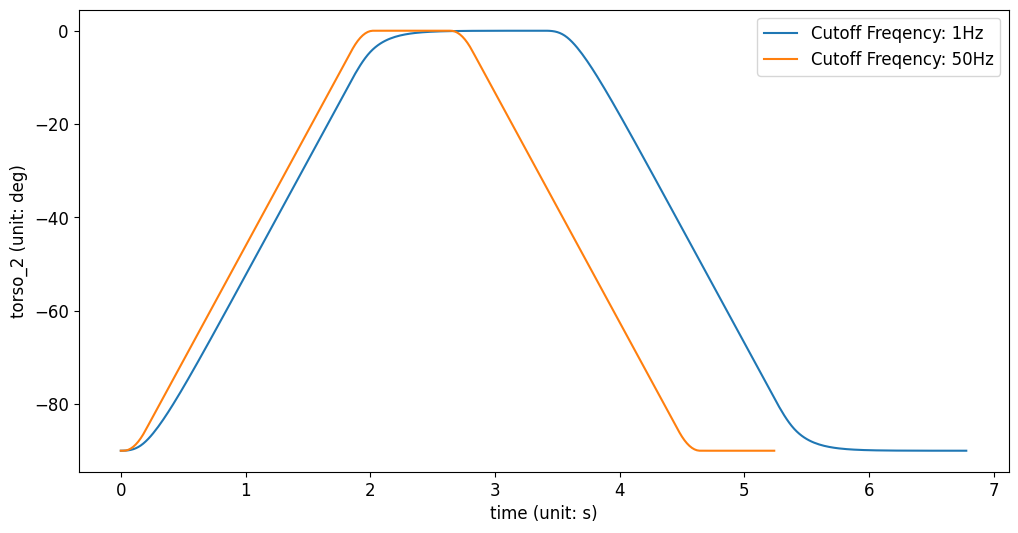

In [12]:
recorded_data = {
    1: np.vstack(ex4_cutoff_frequency(1)),
    50: np.vstack(ex4_cutoff_frequency(50)),
}
robot.stop_state_update()

plt.figure(figsize=(12, 6), facecolor='white', dpi=100)
plt.rcParams.update({'font.size': 12})

plt.plot(np.arange(0, recorded_data[1].shape[0]) * 0.02, np.rad2deg(recorded_data[1][:, 4]),
         np.arange(0, recorded_data[50].shape[0]) * 0.02, np.rad2deg(recorded_data[50][:, 4]))
plt.xlabel('time (unit: s)')
plt.ylabel('torso_2 (unit: deg)')
plt.legend(['Cutoff Freqency: 1Hz', 'Cutoff Freqency: 50Hz'])

# Minimum Time

In [13]:
class Recoder:
    """ContextManager to record target_position and position(encoder)"""

    def __init__(self, robot, record_freq=10):
        self.robot = robot
        self.record_freq = record_freq
        self.target_position = []
        self.position = []
        self.velocity = []
        self.timestamp = []

    # __enter__: with문 들어갈 때 실행
    def __enter__(self):
        self.target_position = []
        self.position = []
        self.velocity = []
        self.timestamp = []

        self.robot.stop_state_update()
        self.robot.start_state_update(self.cb, rate=self.record_freq)

    # __exit__: with문 나올 때 실행
    def __exit__(self, type, value, traceback):
        self.robot.stop_state_update()

    def cb(self, robot_state, control_manager_state):
        self.target_position.append(robot_state.target_position)
        self.position.append(robot_state.position)
        self.velocity.append(robot_state.velocity)

    def add_timestamp(self):
        self.timestamp.append(len(self.position))
        

def ex5_move_right_arm(position, velocity_limit=None, acceleration_limit=None, minimum_time=2.0):
    robot.set_parameter("joint_position_command.cutoff_frequency", "5.0")
    jpc_builder = (
        rby.JointPositionCommandBuilder()
        .set_minimum_time(minimum_time)
        .set_position(position)
    )
    if velocity_limit is not None:
        jpc_builder.set_velocity_limit(velocity_limit)
    if acceleration_limit is not None:
        jpc_builder.set_acceleration_limit(acceleration_limit)

    rc_builder = rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder().set_body_command(
            rby.BodyComponentBasedCommandBuilder()
            # Set Right Command with Joint Position Command
            .set_right_arm_command(jpc_builder)
        )
    )
    rc = robot.send_command(rc_builder).get()
    return rc.finish_code == rby.RobotCommandFeedback.FinishCode.Ok

Text(0.02, 0.5, 'right_arm_3 (unit: deg)')

<Figure size 1200x600 with 0 Axes>

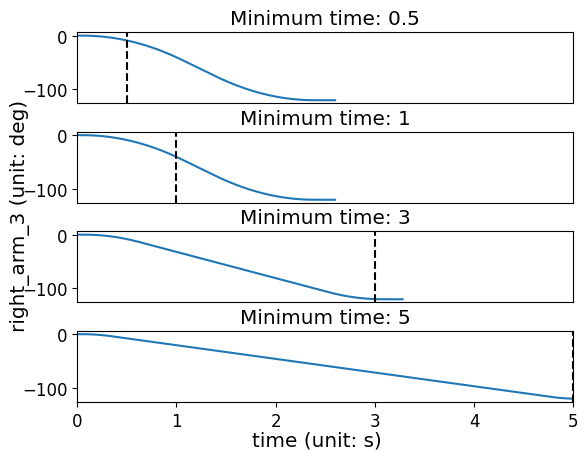

In [51]:
recorder = Recoder(robot, 50)
minimum_times = [0.5, 1, 3, 5]

data = {}
for minimum_time in minimum_times:
    ex5_move_right_arm([0.] * 7, minimum_time=1.)
    time.sleep(1.0)

    with recorder:
        ex5_move_right_arm(np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]), np.deg2rad([90] * 7),
                           np.deg2rad([90] * 7), minimum_time)
    data[minimum_time] = (
        np.vstack(recorder.target_position),
        np.vstack(recorder.position),
        np.vstack(recorder.velocity)
    )
    

### Plot ###
plt.figure(figsize=(12, 6), facecolor='white', dpi=100)
plt.rcParams.update({'font.size': 12})

fig, ax = plt.subplots(4, 1)

for i, minimum_time in enumerate(minimum_times):
    ax[i].set_title(f'Minimum time: {minimum_time}')
    ax[i].plot(np.arange(0, data[minimum_time][0].shape[0]) * 0.02,
               np.rad2deg(data[minimum_time][0][:, model.right_arm_idx[3]]))
    ax[i].axvline(x=minimum_time, color='k', linestyle='--')
    ax[i].set_xlim([0, max(minimum_times)])
    if i != len(minimum_times) - 1:
        ax[i].get_xaxis().set_visible(False)

plt.subplots_adjust(hspace=0.4)
fig.supxlabel('time (unit: s)')
fig.supylabel('right_arm_3 (unit: deg)')

# Command Stream

In [49]:
def ex6_7_move_right_arm_builder(position, velocity_limit=None, acceleration_limit=None, minimum_time=2.0):
    jpc_builder = (
        rby.JointPositionCommandBuilder()
        .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(10))
        .set_minimum_time(minimum_time)
        .set_position(position)
    )
    if velocity_limit is not None:
        jpc_builder.set_velocity_limit(velocity_limit)
    if acceleration_limit is not None:
        jpc_builder.set_acceleration_limit(acceleration_limit)

    rc_builder = rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder().set_body_command(
            rby.BodyComponentBasedCommandBuilder()
            # Set Right Command with Joint Position Command
            .set_right_arm_command(jpc_builder)
        )
    )
    return rc_builder

ex4_move_to(np.deg2rad([0.0, 45.0, -90.0, 45.0, 0.0, 0.0]), np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
            np.deg2rad([0.0, 5.0, 0.0, -120.0, 0.0, 70.0, 0.0]))

True

In [50]:
stream = robot.create_command_stream()

recorder = Recoder(robot, 50)
with recorder:
    for i in range(4):
        recorder.add_timestamp()
        stream.send_command(
            ex6_7_move_right_arm_builder(
                [0.] * 7 if i % 2 == 0 else np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
                np.deg2rad([90] * 7),
                np.deg2rad([90] * 7), minimum_time=3)       # Minimum time = 3sec
        )   
        time.sleep(2.0)                                     # New command is rewritten every 2sec
stream.cancel()
stream.wait()

Text(0, 0.5, 'right_arm_3 (unit: deg)')

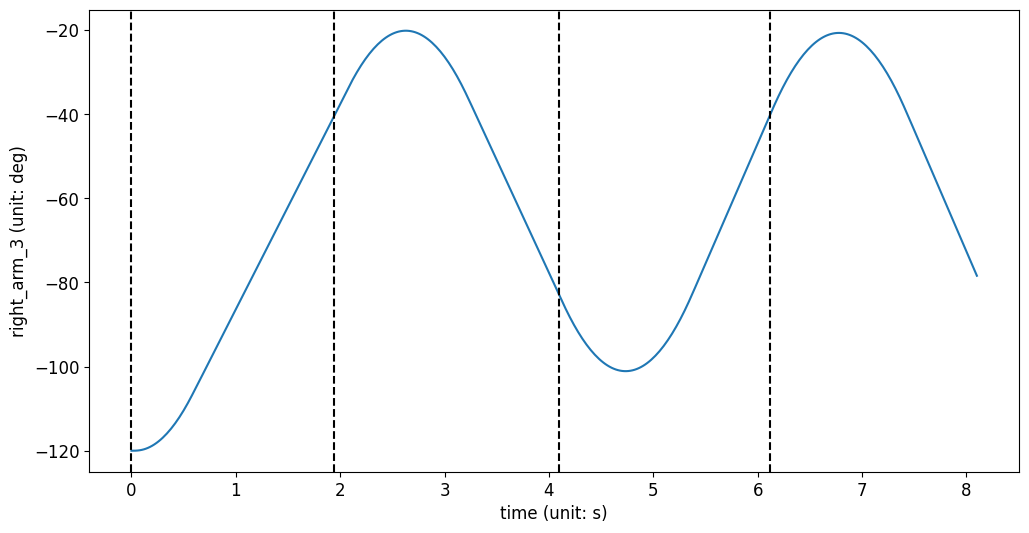

In [17]:
### Plot ###
plt.figure(figsize=(12, 6), facecolor='white', dpi=100)
plt.rcParams.update({'font.size': 12})

tp = np.vstack(recorder.target_position)
plt.plot(np.arange(0, tp.shape[0]) * 0.02, np.rad2deg(tp[:, model.right_arm_idx[3]]))
for ts in recorder.timestamp:
    plt.axvline(x=ts * 0.02, color='k', linestyle='--')
plt.xlabel('time (unit: s)')
plt.ylabel('right_arm_3 (unit: deg)')

# Command Stream with Feedback

In [18]:
robot.wait_for_control_ready(100)
ex4_move_to(np.deg2rad([0.0, 45.0, -90.0, 45.0, 0.0, 0.0]), np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
            np.deg2rad([0.0, 5.0, 0.0, -120.0, 0.0, 70.0, 0.0]))

True

In [19]:
stream = robot.create_command_stream()

recorder = Recoder(robot, 50)
with recorder:
    for i in range(4):
        recorder.add_timestamp()
        stream.send_command(
            ex6_7_move_right_arm_builder(
                [0.] * 7 if i % 2 == 0 else np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
                np.deg2rad([90] * 7),
                np.deg2rad([90] * 7), minimum_time=3)
        )

        start_time = time.monotonic()
        while True:
            feedback = stream.request_feedback()
            if feedback.component_based_command.body_command.body_component_based_command.right_arm_command.joint_position_command.position_based_progress >= 0.7:
                break
            time.sleep(0.1)
robot.cancel_control()
stream.wait()

Text(0, 0.5, 'right_arm_3 (unit: deg)')

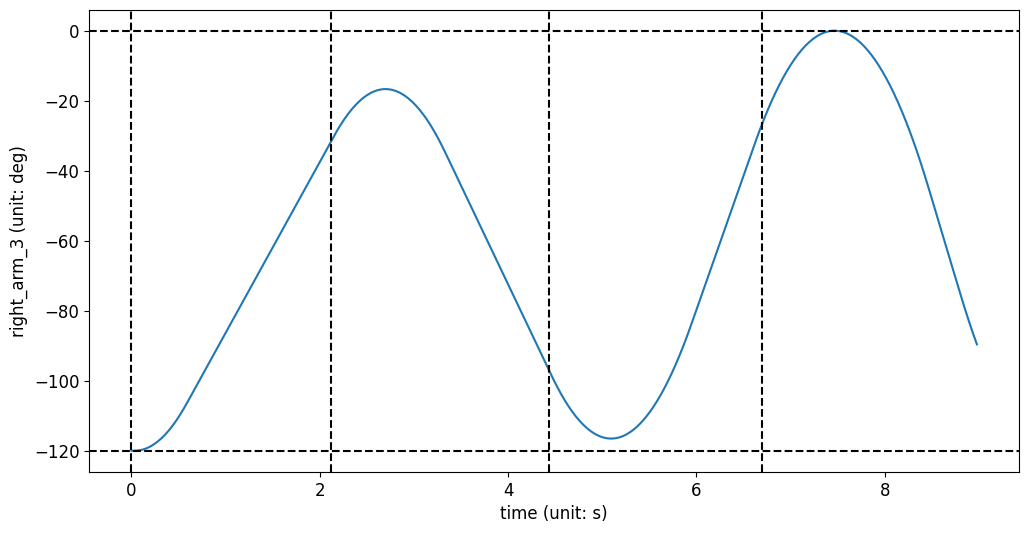

In [20]:
### Plot
plt.figure(figsize=(12, 6), facecolor='white', dpi=100)
plt.rcParams.update({'font.size': 12})

tp = np.vstack(recorder.target_position)
plt.plot(np.arange(0, tp.shape[0]) * 0.02, np.rad2deg(tp[:, model.right_arm_idx[3]]))
plt.axhline(y=0, color='k', linestyle='--')
plt.axhline(y=-120.0, color='k', linestyle='--')
for ts in recorder.timestamp:
    plt.axvline(x=ts * 0.02, color='k', linestyle='--')
plt.xlabel('time (unit: s)')
plt.ylabel('right_arm_3 (unit: deg)')

# Handling Kinematics and Dynamics

In [21]:
robot_model_urdf = robot.get_robot_model()
print("\n".join(robot_model_urdf.splitlines()[:]))        # Show 20 lines of URDF
print("...")

<?xml version="1.0"?>
<robot name="RBY1_A_v1.2">
    <mobile type="differential" xyz="0.228 0 0" rpy="0 0 0" joints="right_wheel left_wheel"
        params="0.53 0.1" /> <!-- wheel_base, wheel_radius -->

    <link name="base">
        <inertial>
            <mass value="60.08042639" />
            <origin rpy="0 0 0" xyz="-0.06157942 -0.00142271 0.13513861" />
            <inertia ixx="1.37742174" ixy="0.02521789" ixz="0.18565467" iyy="2.99386515" iyz="-0.00641869"
                izz="3.76085052" />
        </inertial>

        <visual>
            <geometry>
                <mesh filename="./meshes/base.dae" />
            </geometry>
        </visual>
    </link>

    <link name="wheel_r">
        <inertial>
            <mass value="1.37783736" />
            <origin rpy="0 0 0" xyz="0.0 -0.00073938 0.0" />
            <inertia ixx="0.00426657" ixy="0.0" ixz="0.0" iyy="0.00811815" iyz="0.0" izz="0.00426657" />
        </inertial>

        <visual>
            <geometry>
           

In [22]:
dyn_model = robot.get_dynamics()
dyn_state = dyn_model.make_state(["base", "link_torso_5", "ee_right", "ee_left"], model.robot_joint_names)
BASE_INDEX, LINK_TORSO_5_INDEX, EE_RIGHT_INDEX, EE_LEFT_INDEX = 0, 1, 2, 3

In [23]:
dyn_state.set_q([0] * model.robot_dof)

In [24]:
dyn_model.compute_forward_kinematics(dyn_state)

In [25]:
T_base2right = dyn_model.compute_transformation(dyn_state, BASE_INDEX, EE_RIGHT_INDEX)
print(T_base2right)

[[ 1.     0.     0.     0.   ]
 [ 0.     1.     0.    -0.22 ]
 [ 0.     0.     1.     0.712]
 [ 0.     0.     0.     1.   ]]


In [26]:
dyn_state.set_q(robot.get_state().position)
dyn_model.compute_forward_kinematics(dyn_state)
T_base2right = dyn_model.compute_transformation(dyn_state, BASE_INDEX, EE_RIGHT_INDEX)
print(T_base2right)

[[ 0.771  0.    -0.636  0.369]
 [ 0.044  0.998  0.054 -0.247]
 [ 0.635 -0.07   0.77   0.784]
 [ 0.     0.     0.     1.   ]]


In [27]:
J_base2right = dyn_model.compute_body_jacobian(dyn_state, BASE_INDEX, EE_RIGHT_INDEX)
print(J_base2right)

[[ 0.     0.     0.771  0.044  0.044  0.044  0.771  0.635 -0.175  0.771  0.636  0.    -0.823  0.    -0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.998  0.998  0.998  0.    -0.07   0.961 -0.     0.     1.     0.     1.    -0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.    -0.636  0.054  0.054  0.054 -0.636  0.77  -0.213 -0.636  0.771 -0.     0.567 -0.     1.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.    -0.179  0.154  0.12  -0.228 -0.157  0.207 -0.509  0.    -0.    -0.297 -0.    -0.126 -0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.    -0.485  0.026  0.009  0.026  0.009  0.368 -0.102  0.382  0.369  0.    -0.104 -0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.    -0.217 -0.604 -0.256 -0.289 -0.19  -0.137 -0.04   0.     0.    -0.193  0.     0.     0.     0.     0.     0.     0.     0.     0.

In [28]:
dyn_state.set_gravity([0, 0, 0, 0, 0, -9.81])
print(dyn_model.compute_gravity_term(dyn_state))

[  0.      0.     -3.906 -37.989 106.567 -13.645   0.047   0.    -10.403  -1.75   -0.782  -9.53    0.295  -1.209  -0.    -10.087   1.596   0.945  -9.182  -0.167  -1.423   0.      0.     -0.496]


In [29]:
mass_matrix = dyn_model.compute_mass_matrix(dyn_state)
print(mass_matrix)

[[ 0.008  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.008  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.    27.954  0.06   0.002  0.019  9.952 -1.024  0.477 -1.178 -0.611  0.279  0.06   0.035 -0.001 -0.493 -1.051 -0.701 -0.279  0.097 -0.043 -0.001 -0.054  0.   ]
 [ 0.     0.     0.06  27.975 17.793  9.468  0.019 -0.104 -0.85   0.032  0.042  0.208 -0.01  -0.018  0.    -0.747 -0.023 -0.037  0.426  0.007 -0.012 -0.    -0.009  0.065]
 [ 0.     0.     0.002 17.793 14.83   6.527  0.02  -0.103 -0.622 -0.012  0.015  0.015 -0.002 -0.016  0.    -0.603  0.018 -0.009  0.144  0.002 -0.021 -0.    -0.007  0.038]
 [ 0.     0.     0.019  9.468  6.527  4.273  0.019 -0.102  0.131  0.032  0.027  0.302 -0.009  0.048  0.     0.05  -0.023 -0.03   0.326  0.006  0.

# Cartesian Command with Impedance Control

In [30]:
ex4_move_to([0] * 6, [0] * 7, [0] * 7)
ex4_move_to(np.deg2rad([0.0, 45.0, -90.0, 45.0, 0.0, 0.0]), np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
            np.deg2rad([0.0, 5.0, 0.0, -120.0, 0.0, 70.0, 0.0]))

True

In [45]:
def ex9_command_builder(right_delta_pose):
    dyn_state.set_q(robot.get_state().position)
    dyn_model.compute_forward_kinematics(dyn_state)
    T_torso2right = dyn_model.compute_transformation(dyn_state, LINK_TORSO_5_INDEX, EE_RIGHT_INDEX)

    T_delta = np.eye(4)
    T_delta[0:3, 3] = right_delta_pose
    right_builder = (
        rby.CartesianCommandBuilder()
        .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(100))
        .set_minimum_time(1.5)
        .add_target("link_torso_5", "ee_right", T_torso2right @ T_delta, 1.0, 1.0, 1.0)
        .add_joint_position_target(model.robot_joint_names[model.right_arm_idx[2]], 0)
    )

    T_rel = np.eye(4)
    T_rel[1, 3] = 0.5
    left_builder = (
        rby.ImpedanceControlCommandBuilder()
        .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(100))
        .set_reference_link_name("ee_right")
        .set_link_name("ee_left")
        .set_transformation(T_rel)
        .set_translation_weight([2000, 2000, 2000])
        .set_rotation_weight([200, 200, 200])
    )

    return rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder()
        .set_body_command(
            rby.BodyComponentBasedCommandBuilder()
            .set_right_arm_command(right_builder)
            .set_left_arm_command(left_builder)
        )
    )

In [48]:
right_deltas = [
    [0, -0.05, 0],
    [0, 0.05, 0],
    [0, 0, 0.1],
    [0, 0, -0.1]
]

stream = robot.create_command_stream()
for delta in right_deltas:
    stream.send_command(ex9_command_builder(delta))
    time.sleep(2.0)
stream.cancel()
stream.wait()